Car Price Prediction with Machine Learning

Project Overview

This project uses machine learning to predict car prices based on vehicle characteristics such as engine size, horsepower, fuel type, and other specifications.

Objectives
Explore and prepare car data.
Identify features related to car prices.
Train a regression model.
Evaluate prediction performance.
Understand practical applications of machine learning in price estimation.
Tools Used

Python, Pandas, Matplotlib, Seaborn, and Scikit-learn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("carprice_assignment.csv")

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five rows:")
display(df.head())

Column names:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    objec

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [5]:
# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 5. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Display statistical summary
display(df.describe(include="all"))

Dataset shape: (205, 26)

Column names:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocatio

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205,205,205,205,205,205,205,205.000000,...,205.000000,205,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
unique,NaN,NaN,147,2,2,2,5,3,2,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,toyota corona,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,6,185,168,115,96,120,202,NaN,...,NaN,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,103.000000,0.834146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000


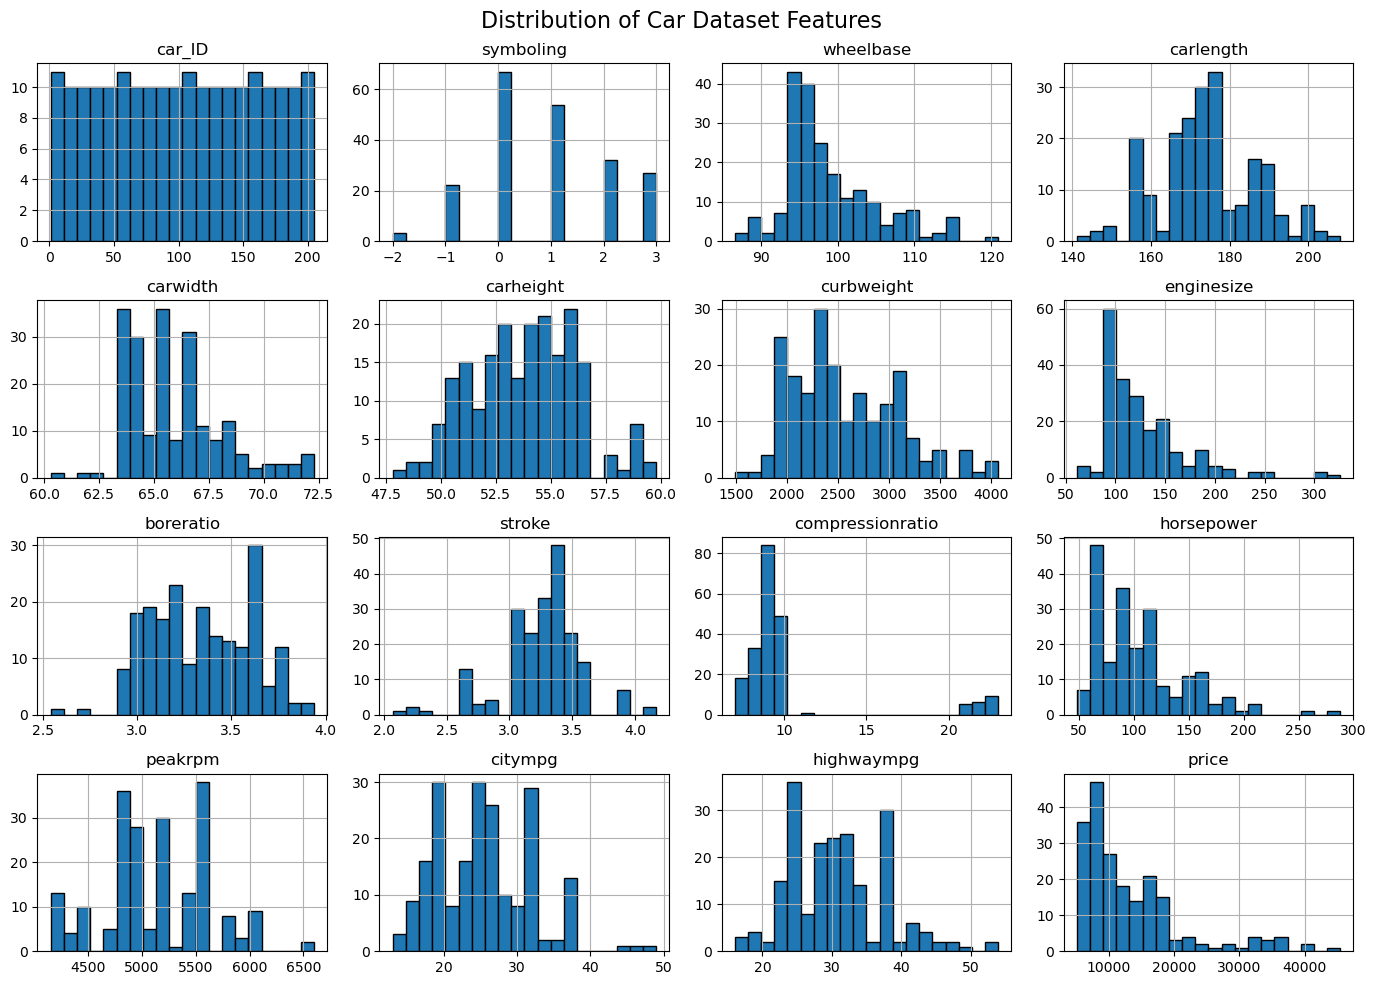

In [6]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Plot histograms
numeric_df.hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle("Distribution of Car Dataset Features", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
print(df.columns.tolist())

['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [8]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("\nDataset shape after removing duplicates:", df.shape)

# Check missing values again
print("\nMissing values after removing duplicates:")
print(df.isnull().sum())

Missing values before cleaning:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Duplicate rows: 0

Dataset shape after removing duplicates: (205, 26)

Missing values after removing duplicates:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carhe

In [9]:
# Identify numerical and categorical columns
numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Fill missing numerical values with median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with most frequent value
for col in categorical_cols:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after filling:")
print(df.isnull().sum())

Missing values after filling:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


Dataset shape: (205, 26)

First five rows:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



Data types:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

Missing values remaining:
0


In [11]:
print(df.columns.tolist())

['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [13]:
# Work on a copy of the cleaned dataset
df_model = df.copy()

# Extract the car brand from the CarName column
df_model["brand"] = (
    df_model["CarName"]
    .astype(str)
    .str.strip()
    .str.split()
    .str[0]
    .str.lower()
)

# Remove the ID and original name columns
df_model = df_model.drop(columns=["car_ID", "CarName"])

print("Brand feature created successfully!")
print("\nBrands in the dataset:")
print(sorted(df_model["brand"].unique()))

print("\nUpdated columns:")
print(df_model.columns.tolist())

Brand feature created successfully!

Brands in the dataset:
['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'maxda', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porcshce', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'vokswagen', 'volkswagen', 'volvo', 'vw']

Updated columns:
['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price', 'brand']


In [14]:
# X = input features
X = df_model.drop(columns=["price"])

# y = price we want to predict
y = df_model["price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nFirst five target prices:")
print(y.head())

Features shape: (205, 24)
Target shape: (205,)

Input features:
['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'brand']

First five target prices:
0    13495.0
1    16500.0
2    16500.0
3    13950.0
4    17450.0
Name: price, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 164
Testing records: 41


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

In [17]:
# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create two regression models
models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ])
}

# Train and evaluate each model
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1835.33,2811.90,0.90
1,Random Forest,1287.18,1826.11,0.96


In [18]:
# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create two regression models
models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ])
}

# Train and evaluate each model
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1835.33,2811.90,0.90
1,Random Forest,1287.18,1826.11,0.96


In [19]:
# Display model comparison
display(results_df.sort_values("RMSE").round(2))

# Select the best model based on RMSE
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Lowest RMSE:", round(results_df["RMSE"].min(), 2))

,Model,MAE,RMSE,R2 Score
1,Random Forest,1287.18,1826.11,0.96
0,Linear Regression,1835.33,2811.90,0.90


Best model: Random Forest
Lowest RMSE: 1826.11


,Feature,Importance
6,num__enginesize,0.575433
5,num__curbweight,0.271665
13,num__highwaympg,0.044571
10,num__horsepower,0.026734
3,num__carwidth,0.012659
2,num__carlength,0.008565
53,cat__brand_bmw,0.007164
1,num__wheelbase,0.007154
12,num__citympg,0.006675
11,num__peakrpm,0.005398


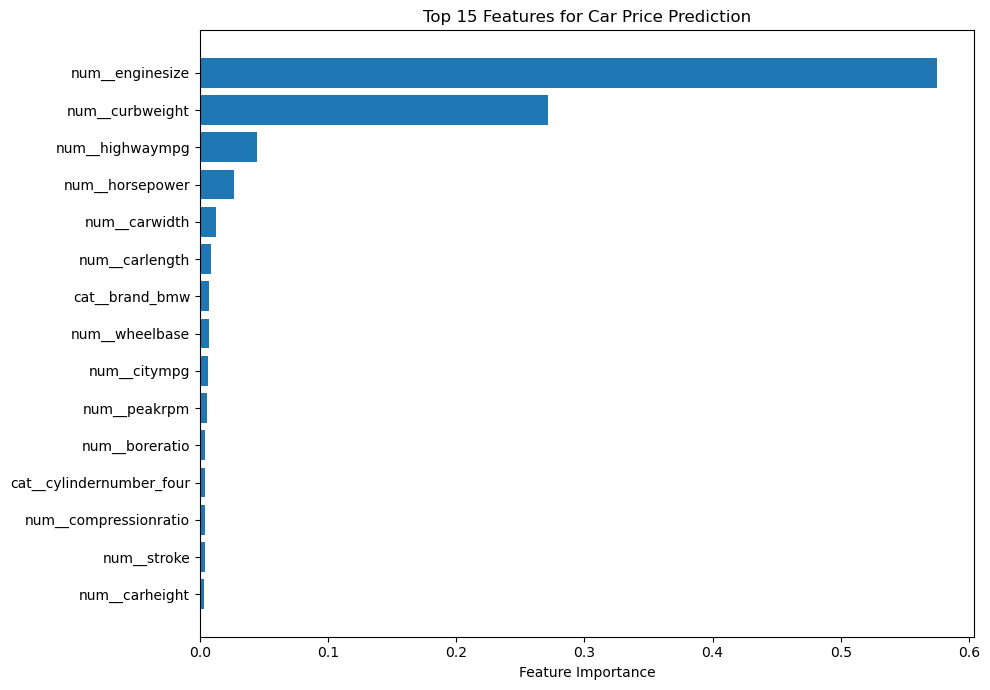

In [20]:
if best_model_name == "Random Forest":

    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_forest = best_model.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_forest.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(15))

    top_features = importance_df.head(15).sort_values("Importance")

    plt.figure(figsize=(10, 7))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Feature Importance")
    plt.title("Top 15 Features for Car Price Prediction")
    plt.tight_layout()
    plt.show()

else:
    print("Linear Regression is the best model.")
    print("Feature importance can be explored using its coefficients.")

In [21]:
# Create an example using an existing test record
new_car = X_test.iloc[[0]].copy()

# Predict its price
predicted_price = best_model.predict(new_car)[0]

actual_price = y_test.iloc[0]

print("Predicted car price:", round(predicted_price, 2))
print("Actual car price:", round(actual_price, 2))
print("Absolute prediction error:",
      round(abs(predicted_price - actual_price), 2))

display(new_car)

Predicted car price: 36205.16
Actual car price: 30760.0
Absolute prediction error: 5445.16


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,brand
15,0,gas,std,four,sedan,rwd,front,103.5,189.0,66.9,...,209,mpfi,3.62,3.39,8.0,182,5400,16,22,bmw


In [22]:
import joblib

joblib.dump(best_model, "car_price_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [23]:
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1835.33,2811.90,0.90
1,Random Forest,1287.18,1826.11,0.96


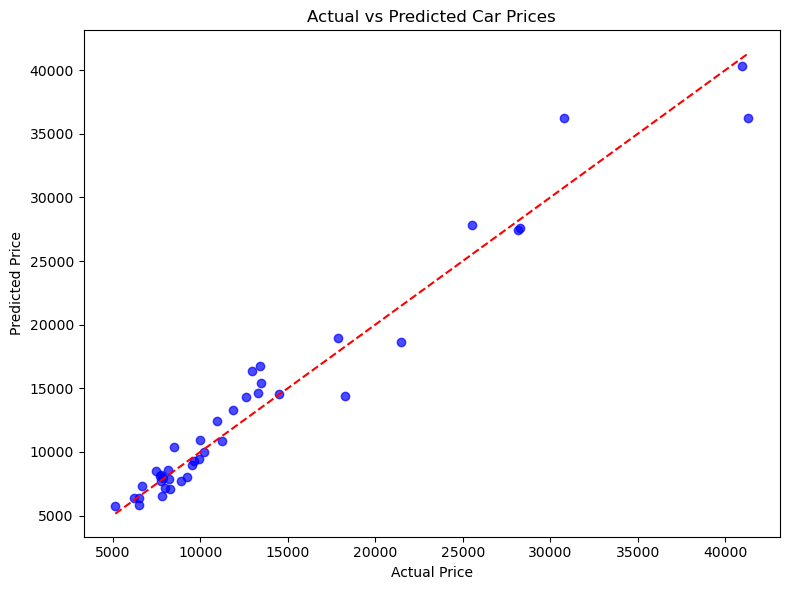

In [24]:
predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, color="blue", alpha=0.7)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.tight_layout()
plt.show()

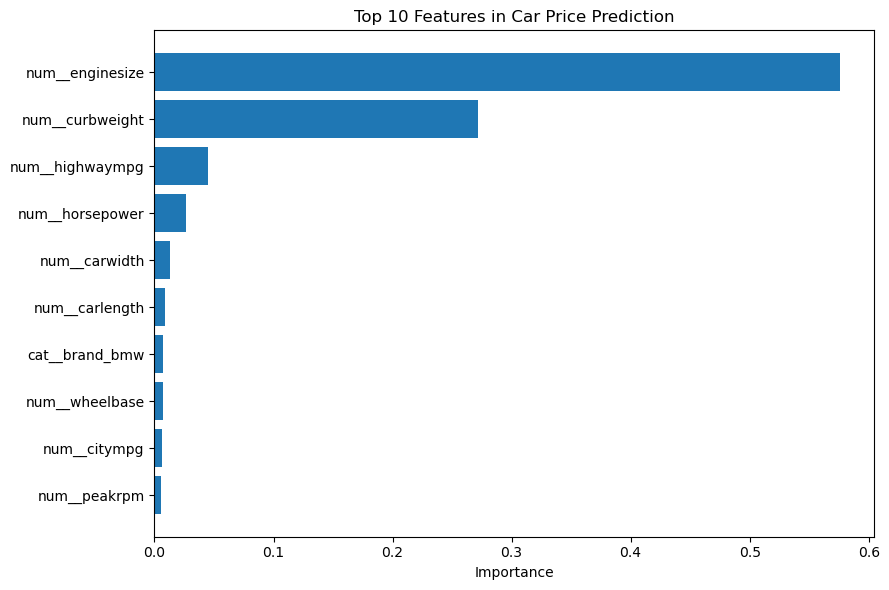

In [25]:
if best_model_name == "Random Forest":
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_model = best_model.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": fitted_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    top_features = importance_df.head(10).sort_values("Importance")

    plt.figure(figsize=(9, 6))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Importance")
    plt.title("Top 10 Features in Car Price Prediction")
    plt.tight_layout()
    plt.show()

else:
    print("Your best model is Linear Regression.")
    print("Use its coefficients for a separate feature analysis.")

In [26]:
def predict_car_price(car_details):
    car_df = pd.DataFrame([car_details])

    predicted_price = best_model.predict(car_df)[0]

    return round(float(predicted_price), 2)


# Use a real row from the test dataset as an example
example_car = X_test.iloc[0].to_dict()

print("Car details:")
print(example_car)

print("\nPredicted price:",
      predict_car_price(example_car))

print("Actual price:", y_test.iloc[0])


Car details:
{'symboling': 0, 'fueltype': 'gas', 'aspiration': 'std', 'doornumber': 'four', 'carbody': 'sedan', 'drivewheel': 'rwd', 'enginelocation': 'front', 'wheelbase': 103.5, 'carlength': 189.0, 'carwidth': 66.9, 'carheight': 55.7, 'curbweight': 3230, 'enginetype': 'ohc', 'cylindernumber': 'six', 'enginesize': 209, 'fuelsystem': 'mpfi', 'boreratio': 3.62, 'stroke': 3.39, 'compressionratio': 8.0, 'horsepower': 182, 'peakrpm': 5400, 'citympg': 16, 'highwaympg': 22, 'brand': 'bmw'}

Predicted price: 36205.16
Actual price: 30760.0


In [27]:
import joblib

joblib.dump(best_model, "car_price_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!
